In [1]:
!pip -q install datasets scikit-learn pandas matplotlib seaborn tqdm

In [2]:
import os, re, math, time, random, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

# Set True for an initial test; False for the full experiment.
QUICK_RUN = True

os.makedirs("outputs", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

Device: cpu
PyTorch: 2.11.0+cpu


In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal=False, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.causal = causal

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attn_dropout = nn.Dropout(dropout)
        self.last_attention = None

    def forward(self, x, key_padding_mask=None):
        # x: (batch, sequence, d_model)
        B, T, C = x.shape

        Q = self.W_q(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.d_head)

        # True means a position is forbidden from being attended to.
        if self.causal:
            causal_mask = torch.triu(
                torch.ones(T, T, device=x.device, dtype=torch.bool),
                diagonal=1
            )
            scores = scores.masked_fill(causal_mask[None, None, :, :],
                                        float("-inf"))

        if key_padding_mask is not None:
            scores = scores.masked_fill(
                key_padding_mask[:, None, None, :],
                float("-inf")
            )

        weights = torch.softmax(scores, dim=-1)
        self.last_attention = weights.detach()
        weights = self.attn_dropout(weights)

        out = weights @ V
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.W_o(out)


class FeedForward(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

In [4]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(
            d_model, n_heads, causal=False, dropout=dropout
        )
        self.ff = FeedForward(d_model, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None):
        x = self.norm1(x + self.drop(self.attn(x, padding_mask)))
        x = self.norm2(x + self.drop(self.ff(x)))
        return x


class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(
            d_model, n_heads, causal=True, dropout=dropout
        )
        self.ff = FeedForward(d_model, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = self.norm1(x + self.drop(self.attn(x)))
        x = self.norm2(x + self.drop(self.ff(x)))
        return x


class NewsTransformer(nn.Module):
    def __init__(self, vocab_size, max_len, d_model=64,
                 n_heads=2, n_layers=2, n_classes=4, dropout=0.1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, n_heads, dropout)
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, n_classes)
        self.max_len = max_len

    def forward(self, input_ids):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        x = self.token_emb(input_ids) + self.pos_emb(positions)[None, :, :]

        padding_mask = input_ids.eq(0)
        for block in self.blocks:
            x = block(x, padding_mask)

        x = self.norm(x)
        # The first token is [CLS].
        return self.classifier(x[:, 0, :])


class LanguageTransformer(nn.Module):
    def __init__(self, vocab_size, max_len=128, d_model=64,
                 n_heads=2, n_layers=2, dropout=0.1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([
            DecoderBlock(d_model, n_heads, dropout)
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)
        self.max_len = max_len

    def forward(self, input_ids):
        B, T = input_ids.shape
        assert T <= self.max_len

        positions = torch.arange(T, device=input_ids.device)
        x = self.token_emb(input_ids) + self.pos_emb(positions)[None, :, :]

        for block in self.blocks:
            x = block(x)

        return self.lm_head(self.norm(x))

In [5]:
raw = load_dataset("fancyzhx/ag_news")

print(raw)
print(raw["train"][0])

LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
PAD, UNK, CLS = "[PAD]", "[UNK]", "[CLS]"

MAX_LEN = 64
VOCAB_LIMIT = 10000 if QUICK_RUN else 15000
N_TRAIN = 4000 if QUICK_RUN else 20000
N_TEST = 2000 if QUICK_RUN else len(raw["test"])

def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", text.lower())

# Balance the training set across all four labels.
train_df = pd.DataFrame(raw["train"])
test_df = pd.DataFrame(raw["test"])

balanced_parts = []
per_class = N_TRAIN // 4
for label in range(4):
    part = train_df[train_df["label"] == label]
    balanced_parts.append(
        part.sample(n=per_class, random_state=SEED)
    )

train_df = pd.concat(balanced_parts).sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

test_df = test_df.groupby("label", group_keys=False).apply(
    lambda x: x.sample(
        n=min(len(x), max(1, N_TEST // 4)),
        random_state=SEED
    )
).reset_index(drop=True)

# Build vocabulary using training data only.
from collections import Counter

counter = Counter()
for text in train_df["text"]:
    counter.update(tokenize(text))

special_tokens = [PAD, UNK, CLS]
most_common = [
    token for token, count in counter.most_common(VOCAB_LIMIT)
    if token not in special_tokens
]

itos = special_tokens + most_common
stoi = {token: i for i, token in enumerate(itos)}
PAD_ID, UNK_ID, CLS_ID = 0, 1, 2

def encode_news(text):
    tokens = [CLS] + tokenize(text)
    ids = [stoi.get(tok, UNK_ID) for tok in tokens[:MAX_LEN]]
    ids += [PAD_ID] * (MAX_LEN - len(ids))
    return ids

class NewsDataset(Dataset):
    def __init__(self, df):
        self.texts = df["text"].tolist()
        self.labels = df["label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(encode_news(self.texts[idx]), dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

BATCH_SIZE = 64

train_loader = DataLoader(
    NewsDataset(train_df), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
test_loader = DataLoader(
    NewsDataset(test_df), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Training samples:", len(train_df))
print("Test samples:", len(test_df))
print("Vocabulary size:", len(itos))
print("Classes:", LABEL_NAMES)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}
Training samples: 4000
Test samples: 2000
Vocabulary size: 10003
Classes: ['World', 'Sports', 'Business', 'Sci/Tech']


/tmp/ipykernel_2964/8508362.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_df = test_df.groupby("label", group_keys=False).apply(


In [6]:
def train_classifier(model, train_loader, epochs=5, lr=3e-4):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=0.01
    )
    criterion = nn.CrossEntropyLoss()
    history = {"loss": [], "epoch_time": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        start = time.time()

        for x, y in tqdm(train_loader, leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * x.size(0)

        avg_loss = total_loss / len(train_loader.dataset)
        history["loss"].append(avg_loss)
        history["epoch_time"].append(time.time() - start)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"loss={avg_loss:.4f} | "
            f"time={history['epoch_time'][-1]:.1f}s"
        )

    return history


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    y_true, y_pred = [], []
    total_loss = 0.0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += F.cross_entropy(
            logits, y, reduction="sum"
        ).item()
        y_pred.extend(logits.argmax(dim=-1).cpu().tolist())
        y_true.extend(y.cpu().tolist())

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    return {
        "loss": total_loss / len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "y_true": y_true,
        "y_pred": y_pred
    }

In [7]:
EPOCHS = 2 if QUICK_RUN else 8

baseline = NewsTransformer(
    vocab_size=len(itos),
    max_len=MAX_LEN,
    d_model=64,
    n_heads=2,
    n_layers=2
)

news_history = train_classifier(
    baseline, train_loader, epochs=EPOCHS
)

news_results = evaluate_classifier(baseline, test_loader)
print({k: v for k, v in news_results.items()
       if k not in ("y_true", "y_pred")})

torch.save(baseline.state_dict(), "checkpoints/news_baseline.pt")

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1/2 | loss=1.4102 | time=10.3s


  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/2 | loss=1.3526 | time=9.2s
{'loss': 1.305791082382202, 'accuracy': 0.4315, 'macro_precision': 0.4775463214400432, 'macro_recall': 0.4315, 'macro_f1': 0.4144093135035836}


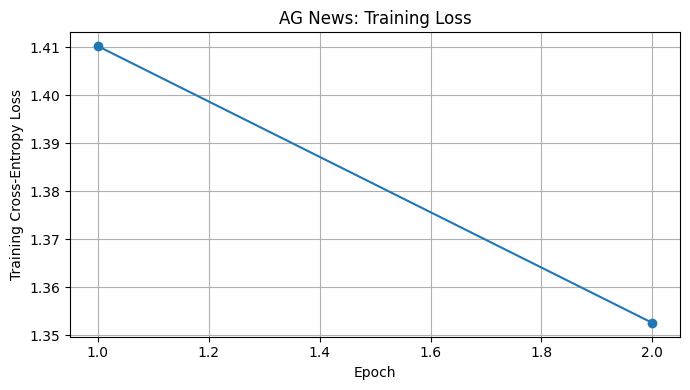

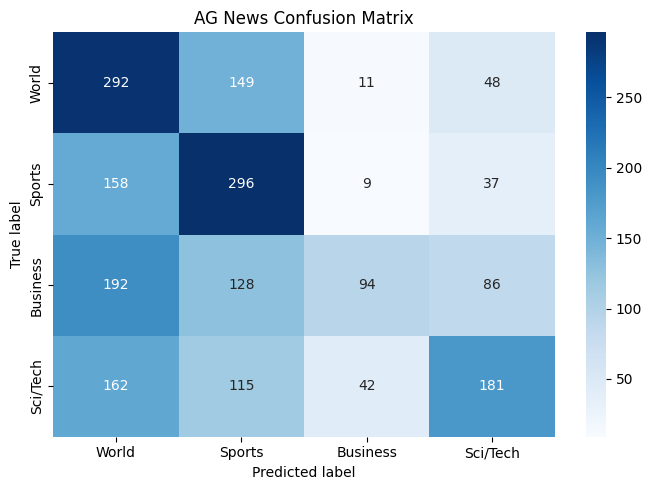

              precision    recall  f1-score   support

       World       0.36      0.58      0.45       500
      Sports       0.43      0.59      0.50       500
    Business       0.60      0.19      0.29       500
    Sci/Tech       0.51      0.36      0.42       500

    accuracy                           0.43      2000
   macro avg       0.48      0.43      0.41      2000
weighted avg       0.48      0.43      0.41      2000



In [8]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(news_history["loss"]) + 1),
         news_history["loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Cross-Entropy Loss")
plt.title("AG News: Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/news_training_loss.png", dpi=160)
plt.show()

cm = confusion_matrix(
    news_results["y_true"], news_results["y_pred"],
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("AG News Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/news_confusion_matrix.png", dpi=160)
plt.show()

print(classification_report(
    news_results["y_true"],
    news_results["y_pred"],
    target_names=LABEL_NAMES,
    zero_division=0
))

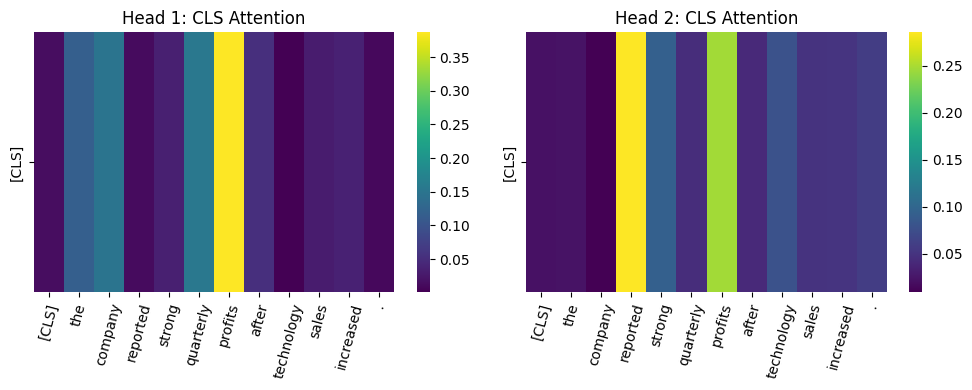

In [9]:
@torch.no_grad()
def plot_news_attention(model, text):
    model.eval()
    ids = torch.tensor(
        [encode_news(text)], dtype=torch.long, device=DEVICE
    )

    x = model.token_emb(ids)
    positions = torch.arange(ids.shape[1], device=DEVICE)
    x = x + model.pos_emb(positions)[None, :, :]

    block = model.blocks[0]
    B, T, C = x.shape

    Q = block.attn.W_q(x).view(
        B, T, block.attn.n_heads, block.attn.d_head
    ).transpose(1, 2)
    K = block.attn.W_k(x).view(
        B, T, block.attn.n_heads, block.attn.d_head
    ).transpose(1, 2)

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(
        block.attn.d_head
    )

    scores = scores.masked_fill(
        ids.eq(PAD_ID)[:, None, None, :], float("-inf")
    )
    weights = scores.softmax(dim=-1)[0, :, 0, :].cpu().numpy()

    tokens = [itos[i] for i in ids[0].cpu().tolist()]
    valid_len = int(ids[0].ne(PAD_ID).sum().item())
    tokens = tokens[:valid_len]
    weights = weights[:, :valid_len]

    fig, axes = plt.subplots(
        1, weights.shape[0],
        figsize=(5 * weights.shape[0], 4),
        squeeze=False
    )
    for h, ax in enumerate(axes[0]):
        sns.heatmap(
            weights[h:h+1], cmap="viridis", ax=ax,
            xticklabels=tokens, yticklabels=["[CLS]"]
        )
        ax.set_title(f"Head {h+1}: CLS Attention")
        ax.tick_params(axis="x", rotation=75)

    plt.tight_layout()
    plt.savefig("outputs/news_attention.png", dpi=160)
    plt.show()

plot_news_attention(
    baseline,
    "The company reported strong quarterly profits after technology sales increased."
)

In [10]:
import urllib.request

SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/"
    "char-rnn/master/data/tinyshakespeare/input.txt"
)

corpus_path = "shakespeare.txt"
if not os.path.exists(corpus_path):
    urllib.request.urlretrieve(SHAKESPEARE_URL, corpus_path)

with open(corpus_path, "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(set(text))
stoi_char = {ch: i for i, ch in enumerate(chars)}
itos_char = {i: ch for ch, i in stoi_char.items()}

encoded = torch.tensor(
    [stoi_char[c] for c in text], dtype=torch.long
)

split = int(0.9 * len(encoded))
train_tokens = encoded[:split]
val_tokens = encoded[split:]

print("Corpus characters:", len(text))
print("Character vocabulary:", len(chars))
print("Vocabulary:", repr("".join(chars)))
print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))

Corpus characters: 1115394
Character vocabulary: 65
Vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Training tokens: 1003854
Validation tokens: 111540


In [11]:
SEQ_LEN = 128
LM_BATCH_SIZE = 64 if not QUICK_RUN else 32

def get_lm_batch(split_name):
    data = train_tokens if split_name == "train" else val_tokens

    ix = torch.randint(
        0, len(data) - SEQ_LEN - 1, (LM_BATCH_SIZE,)
    )
    x = torch.stack([data[i:i+SEQ_LEN] for i in ix])
    y = torch.stack([data[i+1:i+SEQ_LEN+1] for i in ix])

    return x.to(DEVICE), y.to(DEVICE)

In [12]:
@torch.no_grad()
def estimate_lm_loss(model, batches=30):
    model.eval()
    results = {}

    for split_name in ["train", "val"]:
        losses = []
        for _ in range(batches):
            x, y = get_lm_batch(split_name)
            logits = model(x)
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                y.reshape(-1)
            )
            losses.append(loss.item())

        results[split_name] = float(np.mean(losses))

    model.train()
    return results


def train_language_model(model, max_steps=1000, eval_every=100,
                         lr=3e-4):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=0.01
    )
    history = {
        "step": [], "train_loss": [], "val_loss": [],
        "val_ppl": [], "step_time": []
    }

    for step in range(1, max_steps + 1):
        model.train()
        start = time.time()
        x, y = get_lm_batch("train")

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            y.reshape(-1)
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if step == 1 or step % eval_every == 0:
            metrics = estimate_lm_loss(model)
            history["step"].append(step)
            history["train_loss"].append(metrics["train"])
            history["val_loss"].append(metrics["val"])
            history["val_ppl"].append(math.exp(
                min(metrics["val"], 20)
            ))
            history["step_time"].append(time.time() - start)

            print(
                f"Step {step}/{max_steps} | "
                f"train={metrics['train']:.4f} | "
                f"val={metrics['val']:.4f} | "
                f"val PPL={history['val_ppl'][-1]:.2f}"
            )

    return history


def generate_text(model, prompt="ROMEO:", max_new_tokens=500,
                  temperature=0.8, top_k=20):
    model.eval()
    ids = torch.tensor(
        [[stoi_char.get(c, 0) for c in prompt]],
        dtype=torch.long, device=DEVICE
    )

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = ids[:, -SEQ_LEN:]
            logits = model(context)[:, -1, :]
            logits = logits / max(temperature, 1e-5)

            if top_k is not None:
                k = min(top_k, logits.size(-1))
                values, _ = torch.topk(logits, k)
                cutoff = values[:, [-1]]
                logits = logits.masked_fill(
                    logits < cutoff, float("-inf")
                )

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            ids = torch.cat([ids, next_id], dim=1)

    result = "".join(
        itos_char[i] for i in ids[0].cpu().tolist()
    )
    model.train()
    return result

In [13]:
LM_STEPS = 100 if QUICK_RUN else 3000
EVAL_EVERY = 25 if QUICK_RUN else 250

decoder = LanguageTransformer(
    vocab_size=len(chars),
    max_len=SEQ_LEN,
    d_model=64,
    n_heads=2,
    n_layers=2,
    dropout=0.1
)

lm_history = train_language_model(
    decoder,
    max_steps=LM_STEPS,
    eval_every=EVAL_EVERY
)

torch.save(decoder.state_dict(), "checkpoints/lm_baseline.pt")

print("\nGenerated text:\n")
print(generate_text(
    decoder, prompt="ROMEO:", max_new_tokens=500,
    temperature=0.8, top_k=20
))

Step 1/100 | train=4.3151 | val=4.3260 | val PPL=75.64
Step 25/100 | train=3.5528 | val=3.5863 | val PPL=36.10
Step 50/100 | train=3.2483 | val=3.2957 | val PPL=27.00
Step 75/100 | train=3.1180 | val=3.1434 | val PPL=23.18
Step 100/100 | train=2.9722 | val=3.0019 | val PPL=20.12

Generated text:

ROMEO:r
E, e toit:Nst cwind w yr the oratthe:noyon, th
A esd th hi he, ateid su at ateeeigif sr bchluleasct aotas scyoal nge


h m in d ime the t f
Seade s so othot f ii wan theioll
Ns oor tot c oat
I or mored fl
-
I as ot ty ng t in te or t.ee w,,
:or f lotm ar
Q, uoore m he t ito

R tI pthe ud haf,
L dm wh f wimm ac
, t mog a amarr n amtedod f a gd at tyo d, th ts om m. m f iwest ir tonr w the l ar p sm awhl

 t ge fm.




A tho thet h
H t  disnr se uhaf f an, thoo ind t f it mear t cer heerriseooy 


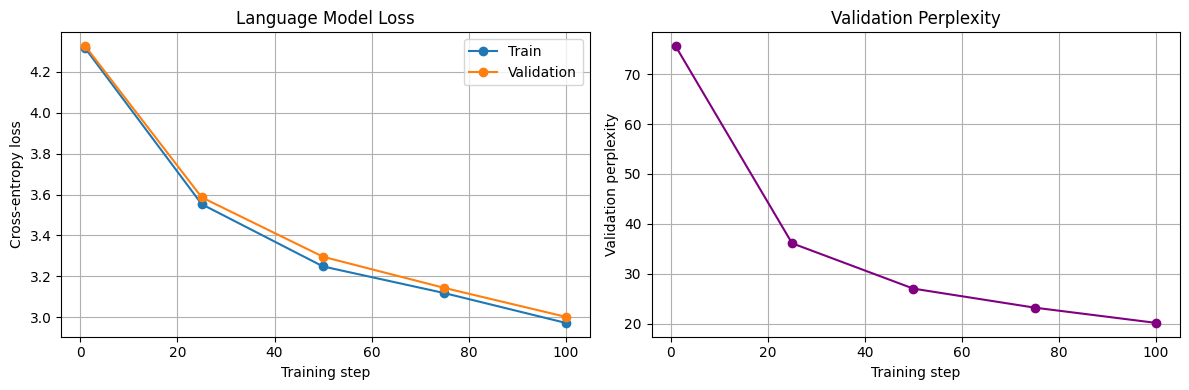

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    lm_history["step"], lm_history["train_loss"],
    marker="o", label="Train"
)
axes[0].plot(
    lm_history["step"], lm_history["val_loss"],
    marker="o", label="Validation"
)
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Language Model Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    lm_history["step"], lm_history["val_ppl"],
    marker="o", color="purple"
)
axes[1].set_xlabel("Training step")
axes[1].set_ylabel("Validation perplexity")
axes[1].set_title("Validation Perplexity")
axes[1].grid(True)

plt.tight_layout()
plt.savefig("outputs/lm_loss_perplexity.png", dpi=160)
plt.show()

In [15]:
for temperature in [0.5, 0.8, 1.2]:
    print(f"\n{'='*20} Temperature = {temperature} {'='*20}")
    print(generate_text(
        decoder,
        prompt="ROMEO:",
        max_new_tokens=300,
        temperature=temperature,
        top_k=20
    ))


==================== Temperature = 0.5 ====================
ROMEO:

S re c ase aood p the ain th t othathe othere the anthe l air, e tee thee an aornd se t aith hee te t the he be aanth


A e t th g s t t e  t n o an ao t aas t e t f b the t s oe wa t t o the s t g thes, the th athe th poth in t te he t han at f d s ous, me t theaer the t o m om toes o n ot tin od

==================== Temperature = 0.8 ====================
ROMEO: tonhe u oe ausd der tene ureloglhusmhati

o t d be ir anon esheyyotd one oorsl the ous t:Rd it dofrss hebSi t oy ealomeanghe t r cr i te m he s goois, s or ciser h ur an harass toog s th.A
Ae f





Ns or m th m adnls hema othe nore


B itid,

SAolsy,


!
N theel s g thets tous s


-en



R thos d 

==================== Temperature = 1.2 ====================
ROMEO:lagsals lonclate y o, sre h,omre mhed,onlhe se ftode ime ryo deerecydi,r m m souot yronrtre  rnrt-t geateyS
Ce edA w y lo n
Hehis,
-oguf o
SIsd p s
Tnrin a hw mornin h t

Reme wfrylo eein,R t for a

In [16]:
if QUICK_RUN:
    CONFIGS = [
        {"d_model": 64, "n_heads": 2, "n_layers": 2},
        {"d_model": 64, "n_heads": 4, "n_layers": 2},
    ]
else:
    CONFIGS = [
        {"d_model": d, "n_heads": h, "n_layers": L}
        for d in [64, 128]
        for h in [2, 4]
        for L in [2, 4, 6, 8]
    ]

encoder_rows = []

for cfg in CONFIGS:
    print("\nRunning encoder configuration:", cfg)

    model = NewsTransformer(
        vocab_size=len(itos),
        max_len=MAX_LEN,
        **cfg
    )

    start = time.time()
    history = train_classifier(
        model, train_loader, epochs=EPOCHS
    )
    elapsed = time.time() - start

    metrics = evaluate_classifier(model, test_loader)

    row = {
        **cfg,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "test_loss": metrics["loss"],
        "mean_epoch_time": np.mean(history["epoch_time"]),
        "total_seconds": elapsed,
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    encoder_rows.append(row)

    filename = (
        f"checkpoints/news_d{cfg['d_model']}_"
        f"h{cfg['n_heads']}_L{cfg['n_layers']}.pt"
    )
    torch.save(model.state_dict(), filename)

encoder_df = pd.DataFrame(encoder_rows)
encoder_df.to_csv("outputs/encoder_experiments.csv", index=False)
display(encoder_df.sort_values("macro_f1", ascending=False))


Running encoder configuration: {'d_model': 64, 'n_heads': 2, 'n_layers': 2}


  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1/2 | loss=1.3828 | time=12.1s


  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/2 | loss=1.3259 | time=9.8s

Running encoder configuration: {'d_model': 64, 'n_heads': 4, 'n_layers': 2}


  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1/2 | loss=1.3904 | time=11.1s


  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/2 | loss=1.3365 | time=12.4s


,d_model,n_heads,n_layers,accuracy,macro_f1,test_loss,mean_epoch_time,total_seconds,parameters
1,64,4,2,0.409,0.399195,1.281960,11.744182,23.490799,744644
0,64,2,2,0.422,0.348671,1.271004,10.932026,21.870586,744644


In [17]:
if QUICK_RUN:
    DECODER_CONFIGS = [
        {"d_model": 64, "n_heads": 2, "n_layers": 2},
        {"d_model": 64, "n_heads": 4, "n_layers": 2},
    ]
else:
    DECODER_CONFIGS = [
        {"d_model": d, "n_heads": h, "n_layers": L}
        for d in [64, 128]
        for h in [2, 4]
        for L in [2, 4, 6, 8]
    ]

decoder_rows = []

for cfg in DECODER_CONFIGS:
    print("\nRunning decoder configuration:", cfg)

    model = LanguageTransformer(
        vocab_size=len(chars),
        max_len=SEQ_LEN,
        dropout=0.1,
        **cfg
    )

    start = time.time()
    history = train_language_model(
        model,
        max_steps=LM_STEPS,
        eval_every=EVAL_EVERY
    )
    elapsed = time.time() - start

    best_val_loss = min(history["val_loss"])

    row = {
        **cfg,
        "best_val_loss": best_val_loss,
        "best_val_ppl": math.exp(min(best_val_loss, 20)),
        "last_val_loss": history["val_loss"][-1],
        "last_val_ppl": history["val_ppl"][-1],
        "total_seconds": elapsed,
        "mean_eval_step_time": np.mean(history["step_time"]),
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    decoder_rows.append(row)

    filename = (
        f"checkpoints/lm_d{cfg['d_model']}_"
        f"h{cfg['n_heads']}_L{cfg['n_layers']}.pt"
    )
    torch.save(model.state_dict(), filename)

decoder_df = pd.DataFrame(decoder_rows)
decoder_df.to_csv("outputs/decoder_experiments.csv", index=False)
display(decoder_df.sort_values("best_val_ppl"))


Running decoder configuration: {'d_model': 64, 'n_heads': 2, 'n_layers': 2}
Step 1/100 | train=4.2780 | val=4.2781 | val PPL=72.10
Step 25/100 | train=3.5309 | val=3.5561 | val PPL=35.03
Step 50/100 | train=3.2666 | val=3.2940 | val PPL=26.95
Step 75/100 | train=3.1021 | val=3.1455 | val PPL=23.23
Step 100/100 | train=2.9900 | val=3.0139 | val PPL=20.37

Running decoder configuration: {'d_model': 64, 'n_heads': 4, 'n_layers': 2}
Step 1/100 | train=4.3747 | val=4.3732 | val PPL=79.30
Step 25/100 | train=3.6237 | val=3.6447 | val PPL=38.27
Step 50/100 | train=3.2699 | val=3.3050 | val PPL=27.25
Step 75/100 | train=3.1189 | val=3.1595 | val PPL=23.56
Step 100/100 | train=3.0014 | val=3.0308 | val PPL=20.71


,d_model,n_heads,n_layers,best_val_loss,best_val_ppl,last_val_loss,last_val_ppl,total_seconds,mean_eval_step_time,parameters
0,64,2,2,3.013906,20.366807,3.013906,20.366807,35.456478,3.530538,116673
1,64,4,2,3.030788,20.713548,3.030788,20.713548,42.430315,4.052748,116673


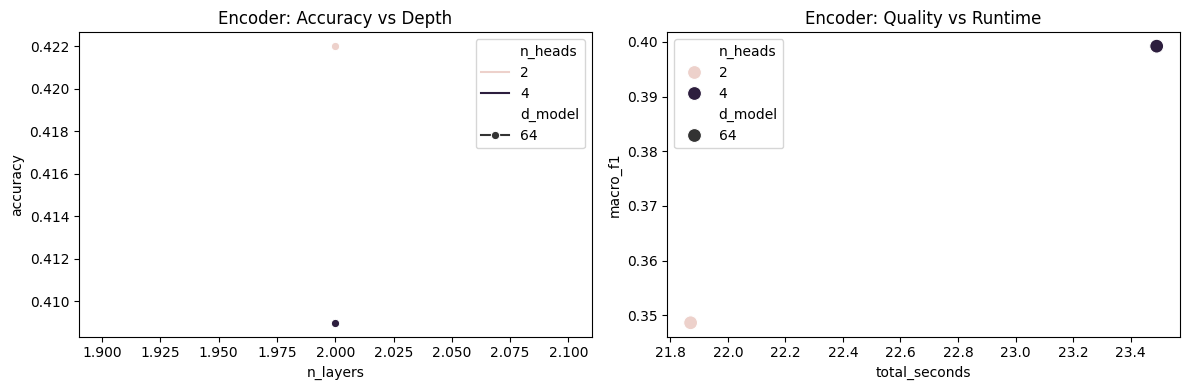

In [19]:
if len(encoder_df):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.lineplot(
        data=encoder_df, x="n_layers", y="accuracy",
        hue="n_heads", style="d_model",
        markers=True, dashes=False, ax=axes[0]
    )
    axes[0].set_title("Encoder: Accuracy vs Depth")

    sns.scatterplot(
        data=encoder_df, x="total_seconds", y="macro_f1",
        hue="n_heads", style="d_model", s=100, ax=axes[1]
    )
    axes[1].set_title("Encoder: Quality vs Runtime")

    plt.tight_layout()
    plt.savefig("outputs/encoder_comparison.png", dpi=160)
    plt.show()

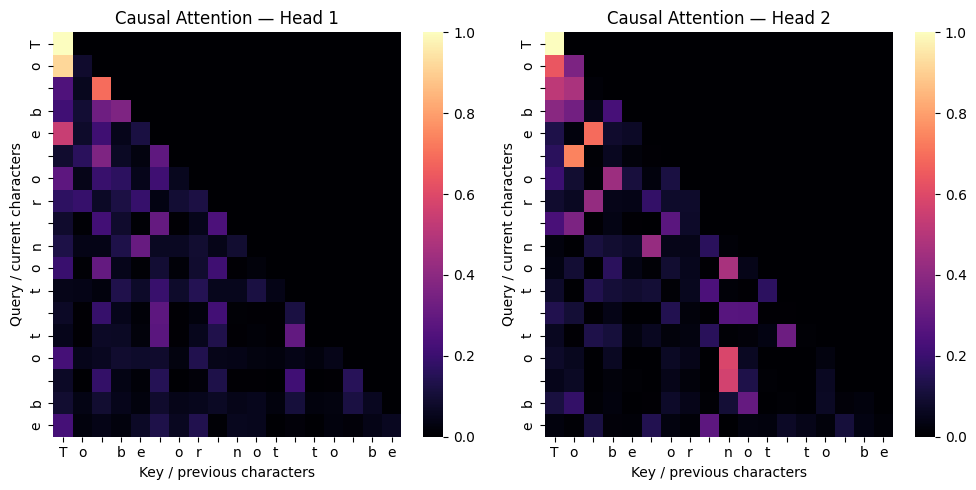

In [21]:
@torch.no_grad()
def plot_causal_attention(model, prompt="To be or not to be"):
    model.eval()

    ids = torch.tensor(
        [[stoi_char.get(c, 0) for c in prompt]],
        dtype=torch.long,
        device=DEVICE
    )

    x = model.token_emb(ids)
    positions = torch.arange(ids.shape[1], device=DEVICE)
    x = x + model.pos_emb(positions)[None, :, :]

    attn = model.blocks[0].attn
    B, T, C = x.shape

    Q = attn.W_q(x).view(
        B, T, attn.n_heads, attn.d_head
    ).transpose(1, 2)
    K = attn.W_k(x).view(
        B, T, attn.n_heads, attn.d_head
    ).transpose(1, 2)

    scores = Q @ K.transpose(-2, -1) / math.sqrt(attn.d_head)

    mask = torch.triu(
        torch.ones(T, T, device=DEVICE, dtype=torch.bool),
        diagonal=1
    )
    scores = scores.masked_fill(mask[None, None], float("-inf"))
    weights = scores.softmax(dim=-1)[0].cpu().numpy()

    fig, axes = plt.subplots(
        1, attn.n_heads,
        figsize=(5 * attn.n_heads, 5),
        squeeze=False
    )

    tokens = list(prompt)
    for h, ax in enumerate(axes[0]):
        sns.heatmap(
            weights[h], cmap="magma", ax=ax,
            xticklabels=tokens, yticklabels=tokens,
            vmin=0
        )
        ax.set_title(f"Causal Attention — Head {h+1}")
        ax.set_xlabel("Key / previous characters")
        ax.set_ylabel("Query / current characters")

    plt.tight_layout()
    plt.savefig("outputs/decoder_attention.png", dpi=160)
    plt.show()
    model.train()

plot_causal_attention(decoder)

In [22]:
from google.colab import drive
drive.mount("/content/drive")

import shutil

SUBMISSION_DIR = "/content/drive/MyDrive/LLM_LAB_Group01/Group01_Assignment5"
os.makedirs(SUBMISSION_DIR, exist_ok=True)

shutil.copytree(
    "outputs",
    os.path.join(SUBMISSION_DIR, "outputs"),
    dirs_exist_ok=True
)
shutil.copytree(
    "checkpoints",
    os.path.join(SUBMISSION_DIR, "checkpoints"),
    dirs_exist_ok=True
)

for filename in ["encoder_experiments.csv", "decoder_experiments.csv"]:
    path = os.path.join("outputs", filename)
    if os.path.exists(path):
        print("Saved:", filename)

print("Saved results to:", SUBMISSION_DIR)

Mounted at /content/drive
Saved: encoder_experiments.csv
Saved: decoder_experiments.csv
Saved results to: /content/drive/MyDrive/LLM_LAB_Group01/Group01_Assignment5
